In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

%matplotlib inline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("Libraries imported successfully.")


Libraries imported successfully.


In [33]:
wine = load_wine(as_frame=True)

df_raw = wine.frame.copy()

df_raw = df_raw.rename(columns={"target": "wine_class"})

class_name_map = {
    i: name for i, name in enumerate(wine.target_names)
}

df_raw["wine_class_name"] = df_raw["wine_class"].map(class_name_map)

print("Wine dataset loaded successfully.")
print("Shape:", df_raw.shape)

display(df_raw.head())


Wine dataset loaded successfully.
Shape: (178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [34]:
print("Columns:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes)

print("\nShape:")
print(df_raw.shape)


Columns:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class', 'wine_class_name']

Data types:


alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
wine_class                        int64
wine_class_name                     str
dtype: object


Shape:
(178, 15)


In [35]:
def make_dirty_wine_dataset(clean_df, random_state=42):
    """
    Create a controlled dirty version of the Wine dataset for teaching data cleaning.
    """

    rng = np.random.default_rng(random_state)

    df_dirty = clean_df.copy()

    # Add a simple identifier column
    df_dirty.insert(
        0,
        "sample_id",
        np.arange(1, len(df_dirty) + 1)
    )

    # Create categorical alcohol level
    df_dirty["alcohol_level"] = pd.cut(
        df_dirty["alcohol"],
        bins=[0, 12.5, 13.5, np.inf],
        labels=["low", "medium", "high"]
    ).astype("object")

    # Introduce inconsistent category formatting
    df_dirty.loc[0, "alcohol_level"] = "High "
    df_dirty.loc[1, "alcohol_level"] = "high"
    df_dirty.loc[2, "alcohol_level"] = "MEDIUM"
    df_dirty.loc[3, "alcohol_level"] = " medium "
    df_dirty.loc[4, "alcohol_level"] = "Low"
    df_dirty.loc[5, "alcohol_level"] = "unknown"

    # Introduce missing values
    missing_plan = {
        "alcohol": 8,
        "malic_acid": 10,
        "flavanoids": 9,
        "proline": 7
    }

    for column, n_missing in missing_plan.items():
        missing_rows = rng.choice(
            df_dirty.index,
            size=n_missing,
            replace=False
        )

        df_dirty.loc[missing_rows, column] = np.nan

    # Missing categorical values
    cat_missing_rows = rng.choice(
        df_dirty.index,
        size=5,
        replace=False
    )

    df_dirty.loc[
        cat_missing_rows,
        "alcohol_level"
    ] = np.nan

    # Invalid negative values
    df_dirty.loc[8, "alcohol"] = -13.0
    df_dirty.loc[12, "proline"] = -999.0

    # Suspicious outliers
    df_dirty.loc[20, "proline"] = 5000.0
    df_dirty.loc[25, "color_intensity"] = 25.0

    # Add duplicate records
    duplicate_rows = df_dirty.iloc[[10, 30]].copy()

    df_dirty = pd.concat(
        [df_dirty, duplicate_rows],
        ignore_index=True
    )

    return df_dirty


In [36]:
df_dirty = make_dirty_wine_dataset(df_raw)

print("Dirty dataset created successfully!")
print("Shape:", df_dirty.shape)

display(df_dirty.head(10))


Dirty dataset created successfully!
Shape: (180, 17)


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0,High
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0,high
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0,MEDIUM
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0,medium
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0,Low
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0,class_0,unknown
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,class_0,high
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,NaN,0,class_0,high
8,9,-13.00,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,class_0,high
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,class_0,high


In [37]:
display(df_dirty.head(10))

,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0,High
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0,high
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0,MEDIUM
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0,medium
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0,Low
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0,class_0,unknown
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,class_0,high
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,NaN,0,class_0,high
8,9,-13.00,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,class_0,high
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,class_0,high


In [38]:
print("Shape:")
print(df_dirty.shape)

print("\nColumns:")
print(df_dirty.columns.tolist())


Shape:
(180, 17)

Columns:
['sample_id', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class', 'wine_class_name', 'alcohol_level']


In [39]:
missing_values = df_dirty.isna().sum()

print("Missing values:")
display(missing_values[missing_values > 0])


Missing values:


alcohol           8
malic_acid       10
flavanoids       10
proline           7
alcohol_level     5
dtype: int64

In [40]:
duplicate_count = df_dirty.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 2


In [41]:
display(df_dirty.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,180.0,NaN,NaN,NaN,88.738889,51.753861,1.0,43.75,88.5,133.25,178.0
alcohol,172.0,NaN,NaN,NaN,12.871221,2.138527,-13.0,12.3675,13.05,13.71,14.75
malic_acid,170.0,NaN,NaN,NaN,2.296059,1.097297,0.74,1.575,1.82,3.03,5.8
ash,180.0,NaN,NaN,NaN,2.368,0.273984,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,180.0,NaN,NaN,NaN,19.503333,3.330306,10.6,17.2,19.5,21.5,30.0
magnesium,180.0,NaN,NaN,NaN,99.777778,14.208171,70.0,88.0,98.0,107.0,162.0
total_phenols,180.0,NaN,NaN,NaN,2.302667,0.62644,0.98,1.7475,2.38,2.8,3.88
flavanoids,170.0,NaN,NaN,NaN,2.039294,0.99849,0.34,1.2275,2.135,2.875,5.08
nonflavanoid_phenols,180.0,NaN,NaN,NaN,0.360667,0.12432,0.13,0.2675,0.34,0.4325,0.66
proanthocyanins,180.0,NaN,NaN,NaN,1.599667,0.575165,0.41,1.25,1.56,1.9625,3.58


In [43]:
target_column = "wine_class"
identifier_column = "sample_id"

numerical_columns = df_dirty.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df_dirty.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Target column:", target_column)
print("Identifier column:", identifier_column)

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)


Target column: wine_class
Identifier column: sample_id

Numerical columns:
['sample_id', 'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'wine_class']

Categorical columns:
['wine_class_name', 'alcohol_level']


In [44]:
df_clean = df_dirty.copy()

df_clean["alcohol_missing"] = df_clean["alcohol"].isna().astype(int)
df_clean["proline_missing"] = df_clean["proline"].isna().astype(int)

print("Missing indicator columns created.")

display(
    df_clean[
        ["alcohol", "alcohol_missing", "proline", "proline_missing"]
    ].head(10)
)


Missing indicator columns created.


,alcohol,alcohol_missing,proline,proline_missing
0,14.23,0,1065.0,0
1,13.20,0,1050.0,0
2,13.16,0,1185.0,0
3,14.37,0,1480.0,0
4,13.24,0,735.0,0
5,14.20,0,1450.0,0
6,14.39,0,1290.0,0
7,14.06,0,NaN,1
8,-13.00,0,1045.0,0
9,13.86,0,1045.0,0


In [45]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

after_duplicates = len(df_clean)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Rows before removing duplicates: 180
Rows after removing duplicates: 178
Duplicates removed: 2


In [46]:
positive_columns = [
    "alcohol",
    "malic_acid",
    "flavanoids",
    "proline",
    "color_intensity"
]

for column in positive_columns:
    invalid_mask = df_clean[column] < 0
    invalid_count = invalid_mask.sum()

    if invalid_count > 0:
        print(
            f"{column}: {invalid_count} invalid negative value(s) found."
        )

        df_clean.loc[invalid_mask, column] = np.nan


alcohol: 1 invalid negative value(s) found.
proline: 1 invalid negative value(s) found.


In [47]:
df_clean["alcohol_level"] = (
    df_clean["alcohol_level"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df_clean["alcohol_level"] = df_clean[
    "alcohol_level"
].replace("unknown", pd.NA)

print("Cleaned alcohol_level categories:")
print(df_clean["alcohol_level"].value_counts(dropna=False))


Cleaned alcohol_level categories:
alcohol_level
medium    63
low       57
high      52
<NA>       6
Name: count, dtype: Int64


In [48]:
df_clean["alcohol_level_missing"] = (
    df_clean["alcohol_level"].isna().astype(int)
)

print("Categorical missing indicator created.")

display(
    df_clean[
        ["alcohol_level", "alcohol_level_missing"]
    ].head(10)
)


Categorical missing indicator created.


,alcohol_level,alcohol_level_missing
0,high,0
1,high,0
2,medium,0
3,medium,0
4,low,0
5,<NA>,1
6,high,0
7,high,0
8,high,0
9,high,0


In [49]:
print("Missing values before imputation:")

missing_before_imputation = df_clean.isna().sum()

display(
    missing_before_imputation[
        missing_before_imputation > 0
    ]
)

Missing values before imputation:


alcohol           9
malic_acid       10
flavanoids        9
proline           8
alcohol_level     6
dtype: int64

In [50]:
numerical_for_imputation = [
    "alcohol",
    "malic_acid",
    "flavanoids",
    "proline",
    "color_intensity"
]

for column in numerical_for_imputation:
    median_value = df_clean[column].median()

    df_clean[column] = df_clean[column].fillna(
        median_value
    )

print("Numerical missing values filled using the median.")

Numerical missing values filled using the median.


In [51]:
alcohol_level_mode = df_clean["alcohol_level"].mode()[0]

df_clean["alcohol_level"] = df_clean[
    "alcohol_level"
].fillna(alcohol_level_mode)

print("Alcohol level missing values filled using the mode.")
print("Mode:", alcohol_level_mode)

Alcohol level missing values filled using the mode.
Mode: medium


In [52]:
remaining_missing = df_clean.isna().sum()

print("Remaining missing values:")

display(
    remaining_missing[
        remaining_missing > 0
    ]
)

if remaining_missing.sum() == 0:
    print("No missing values remain.")

Remaining missing values:


Series([], dtype: int64)

No missing values remain.


In [53]:
df_clean["phenol_flavanoid_ratio"] = (
    df_clean["total_phenols"] /
    df_clean["flavanoids"]
)

df_clean["proline_per_alcohol"] = (
    df_clean["proline"] /
    df_clean["alcohol"]
)

print("Derived columns created.")

display(
    df_clean[
        [
            "total_phenols",
            "flavanoids",
            "phenol_flavanoid_ratio",
            "proline",
            "alcohol",
            "proline_per_alcohol"
        ]
    ].head(10)
)

Derived columns created.


,total_phenols,flavanoids,phenol_flavanoid_ratio,proline,alcohol,proline_per_alcohol
0,2.80,3.06,0.915033,1065.0,14.23,74.841883
1,2.65,2.76,0.960145,1050.0,13.20,79.545455
2,2.80,3.24,0.864198,1185.0,13.16,90.045593
3,3.85,3.49,1.103152,1480.0,14.37,102.992345
4,2.80,2.69,1.040892,735.0,13.24,55.513595
5,3.27,3.39,0.964602,1450.0,14.20,102.112676
6,2.50,2.52,0.992063,1290.0,14.39,89.645587
7,2.60,2.51,1.035857,666.0,14.06,47.368421
8,2.80,2.98,0.939597,1045.0,13.05,80.076628
9,2.98,3.15,0.946032,1045.0,13.86,75.396825


In [54]:
grouped_comparison = df_clean.groupby(
    "wine_class_name"
)[
    [
        "alcohol",
        "flavanoids",
        "proline",
        "phenol_flavanoid_ratio"
    ]
].mean()

display(grouped_comparison)

,alcohol,flavanoids,proline,phenol_flavanoid_ratio
wine_class_name,,,,
class_0,13.704746,2.945424,1145.355932,0.973270
class_1,12.338310,2.061831,521.380282,1.159575
class_2,13.163958,0.883958,629.895833,2.233161


In [55]:
grouped_statistics = df_clean.groupby(
    "wine_class_name"
)[
    ["alcohol", "proline"]
].agg(
    ["mean", "median"]
)

display(grouped_statistics)

alcohol              proline        
                      mean  median         mean  median
wine_class_name                                        
class_0          13.704746  13.740  1145.355932  1065.0
class_1          12.338310  12.330   521.380282   495.0
class_2          13.163958  13.135   629.895833   627.5

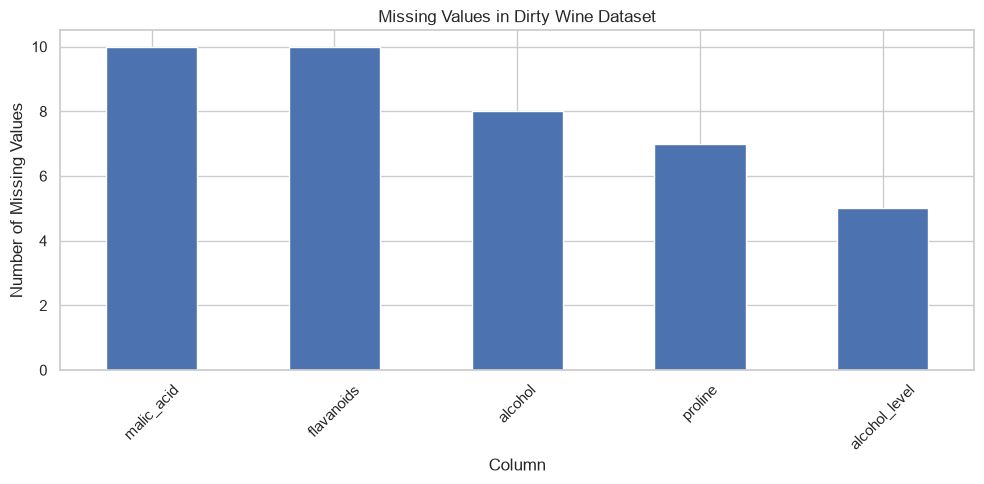

In [56]:
missing_counts = df_dirty.isna().sum()

missing_counts = missing_counts[
    missing_counts > 0
].sort_values(ascending=False)

plt.figure(figsize=(10, 5))

missing_counts.plot(kind="bar")

plt.title("Missing Values in Dirty Wine Dataset")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

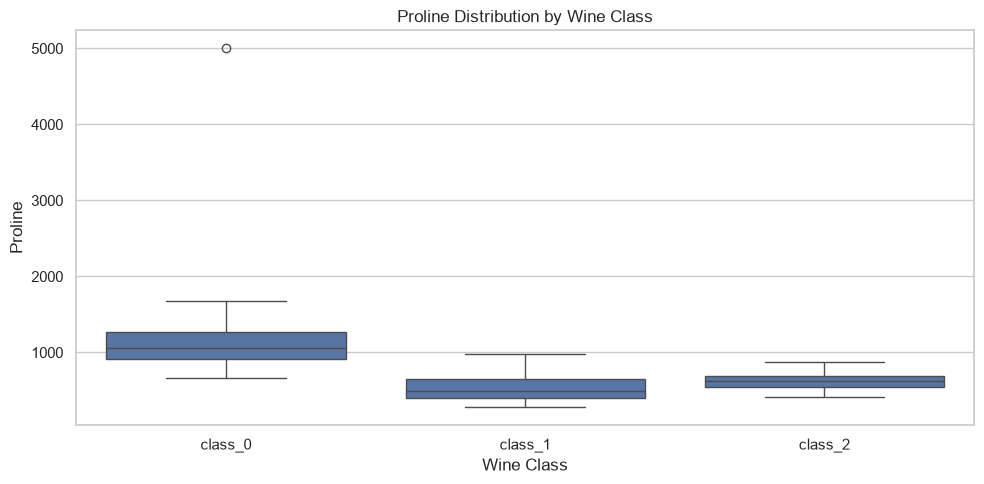

In [57]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="wine_class_name",
    y="proline"
)

plt.title("Proline Distribution by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Proline")

plt.tight_layout()
plt.show()


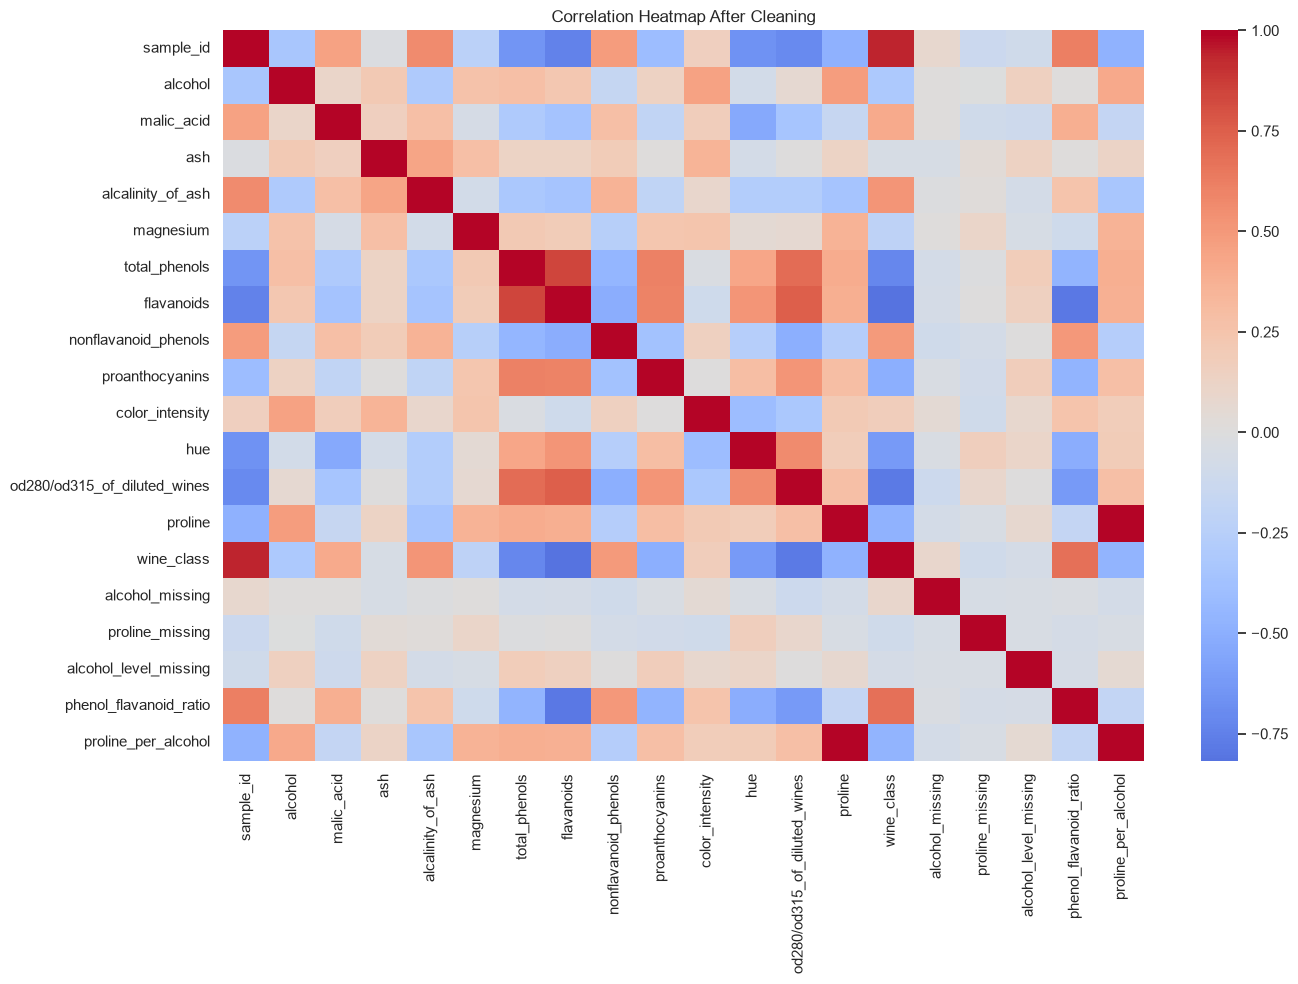

In [58]:
numeric_clean = df_clean.select_dtypes(
    include=np.number
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_clean.corr(),
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap After Cleaning")

plt.tight_layout()
plt.show()

In [59]:
X = df_clean.drop(
    columns=["wine_class", "wine_class_name"]
)

y = df_clean["wine_class"]

# Remove identifier because it is not a useful predictive feature
X = X.drop(columns=["sample_id"])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (178, 19)
y shape: (178,)


In [60]:
numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numeric_cols)

print("\nCategorical features:")
print(categorical_cols)

Numerical features:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'alcohol_missing', 'proline_missing', 'alcohol_level_missing', 'phenol_flavanoid_ratio', 'proline_per_alcohol']

Categorical features:
['alcohol_level']


In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (142, 19)
Test set: (36, 19)


In [62]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical pipeline created.")

Numerical pipeline created.


In [63]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

print("Categorical pipeline created.")

Categorical pipeline created.


In [64]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_cols
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_cols
        )
    ]
)

print("ColumnTransformer created.")


ColumnTransformer created.


In [65]:
X_train_ready = preprocessor.fit_transform(X_train)

X_test_ready = preprocessor.transform(X_test)

print("Training data transformed:", X_train_ready.shape)
print("Test data transformed:", X_test_ready.shape)

Training data transformed: (142, 21)
Test data transformed: (36, 21)


In [66]:
print("Preprocessing completed successfully.")

print("\nTraining data shape:")
print(X_train_ready.shape)

print("\nTest data shape:")
print(X_test_ready.shape)

Preprocessing completed successfully.

Training data shape:
(142, 21)

Test data shape:
(36, 21)


In [67]:
print("Final cleaned dataset shape:", df_clean.shape)

display(df_clean.head(10))

Final cleaned dataset shape: (178, 22)


,sample_id,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class,wine_class_name,alcohol_level,alcohol_missing,proline_missing,alcohol_level_missing,phenol_flavanoid_ratio,proline_per_alcohol
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0,high,0,0,0,0.915033,74.841883
1,2,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0,high,0,0,0,0.960145,79.545455
2,3,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0,medium,0,0,0,0.864198,90.045593
3,4,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0,medium,0,0,0,1.103152,102.992345
4,5,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0,low,0,0,0,1.040892,55.513595
5,6,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0,class_0,medium,0,0,1,0.964602,102.112676
6,7,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0,class_0,high,0,0,0,0.992063,89.645587
7,8,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,666.0,0,class_0,high,0,1,0,1.035857,47.368421
8,9,13.05,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0,class_0,high,0,0,0,0.939597,80.076628
9,10,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0,class_0,high,0,0,0,0.946032,75.396825


In [68]:
print("Total missing values in cleaned dataset:")

print(df_clean.isna().sum().sum())

Total missing values in cleaned dataset:
0


In [69]:
print(
    "Total duplicate rows in cleaned dataset:",
    df_clean.duplicated().sum()
)

Total duplicate rows in cleaned dataset: 0


The most important data-quality problems in this dataset were missing values, invalid negative values, inconsistent categorical labels, duplicate records, and suspicious outliers. Missing values could affect calculations and model training, while invalid negative values were not meaningful for positive-only features such as alcohol and proline. The inconsistent values in the alcohol_level column could also cause the same category to be treated as different categories. These problems were addressed by removing duplicates, converting invalid values to missing values, standardizing category labels, and using median or mode imputation.


Safe preprocessing is important because information from the test set should not be used when preparing the training data. If statistics such as the median, mode, or scaling parameters are calculated using the complete dataset before splitting, information from the test set can leak into the training process. This can make future AI models appear to perform better than they actually do on unseen data. A train-test split combined with a ColumnTransformer and pipelines helps ensure that preprocessing is learned from the training data and then applied to the test data consistently.


In [70]:
print("========== FINAL SUMMARY ==========")

print("Original dataset shape:", df_raw.shape)
print("Dirty dataset shape:", df_dirty.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:",
      df_clean.isna().sum().sum())

print("Remaining duplicate rows:",
      df_clean.duplicated().sum())

print("\nTraining transformed shape:",
      X_train_ready.shape)

print("Test transformed shape:",
      X_test_ready.shape)

print("\nMini-project completed successfully!")

========== FINAL SUMMARY ==========
Original dataset shape: (178, 15)
Dirty dataset shape: (180, 17)
Cleaned dataset shape: (178, 22)

Remaining missing values: 0
Remaining duplicate rows: 0

Training transformed shape: (142, 21)
Test transformed shape: (36, 21)

Mini-project completed successfully!
